In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import hog

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [3]:
DATA_DIR = Path("../data/FIRE-SMOKE-DATASET/").resolve()

TRAIN_DIR = DATA_DIR / "Train"
TEST_DIR = DATA_DIR / "Test"

classes = ["Fire", "Smoke", "Neutral"]

print("Train exists:", TRAIN_DIR.exists())
print("Test exists:", TEST_DIR.exists())

FEATURE_DIR = DATA_DIR / "features"

Train exists: True
Test exists: True


In [4]:
data = np.load(
    FEATURE_DIR / "color_features.npz"
)

train_paths = data["train_paths"]
val_paths = data["val_paths"]

y_train = data["y_train"]
y_val = data["y_val"]

In [5]:
def prepare_hog_image(image_path, size=(128, 128)):

    img = cv2.imread(str(image_path))

    if img is None:
        raise ValueError(f"Cannot read {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    resized = cv2.resize(
        gray,
        size,
        interpolation=cv2.INTER_AREA
    )

    return resized

HOG feature shape: (8100,)


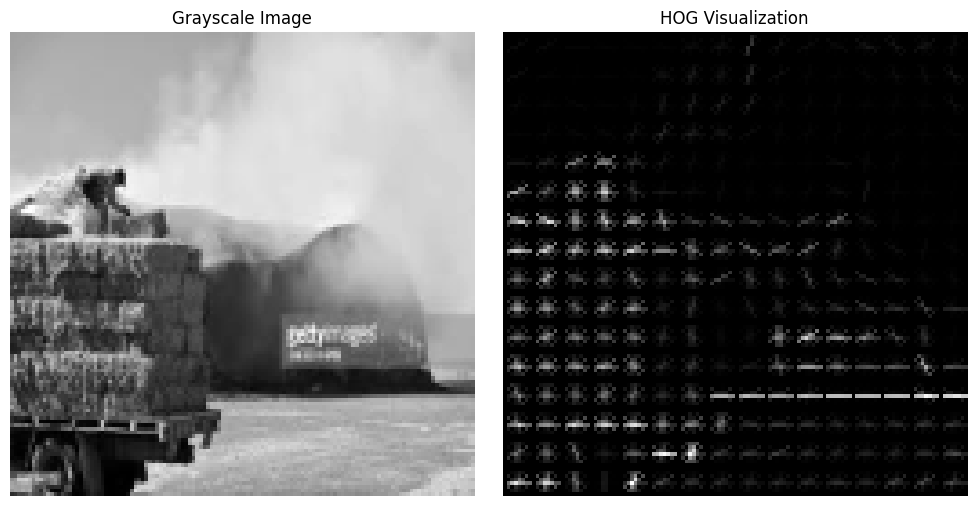

In [6]:
img = prepare_hog_image(train_paths[0])

hog_features, hog_visualization = hog(
    img,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True,
    feature_vector=True
)

print("HOG feature shape:", hog_features.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Grayscale Image")
axes[0].axis("off")

axes[1].imshow(hog_visualization, cmap="gray")
axes[1].set_title("HOG Visualization")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [7]:
def extract_hog_features(image_path):

    img = prepare_hog_image(image_path)

    features = hog(
        img,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        visualize=False,
        feature_vector=True
    )

    return features.astype(np.float32)

In [8]:
X_train_hog = np.vstack([
    extract_hog_features(p)
    for p in train_paths
])

X_val_hog = np.vstack([
    extract_hog_features(p)
    for p in val_paths
])

print("Training HOG:", X_train_hog.shape)
print("Validation HOG:", X_val_hog.shape)

Training HOG: (2160, 8100)
Validation HOG: (540, 8100)


HOG Validation Accuracy: 0.6648148148148149
              precision    recall  f1-score   support

        Fire       0.63      0.68      0.66       180
       Smoke       0.57      0.51      0.54       180
     Neutral       0.78      0.81      0.79       180

    accuracy                           0.66       540
   macro avg       0.66      0.66      0.66       540
weighted avg       0.66      0.66      0.66       540



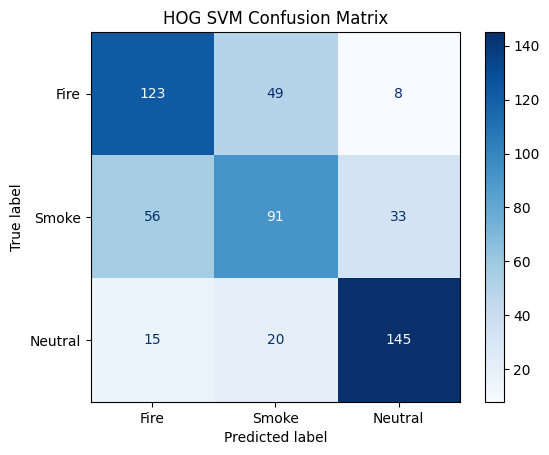

In [9]:
hog_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )
)

hog_svm.fit(X_train_hog, y_train)

y_pred_hog = hog_svm.predict(X_val_hog)

print(
    "HOG Validation Accuracy:",
    accuracy_score(y_val, y_pred_hog)
)

print(
    classification_report(
        y_val,
        y_pred_hog,
        target_names=classes
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_hog,
    display_labels=classes,
    cmap="Blues"
)

plt.title("HOG SVM Confusion Matrix")
plt.show()

### HOG + HSV

In [10]:
X_train_color = data["X_train"]
X_val_color = data["X_val"]

y_train = data["y_train"]
y_val = data["y_val"]

In [11]:
from sklearn.preprocessing import StandardScaler

color_scaler = StandardScaler()
hog_scaler = StandardScaler()

color_train = color_scaler.fit_transform(X_train_color)
color_val = color_scaler.transform(X_val_color)

hog_train = hog_scaler.fit_transform(X_train_hog)
hog_val = hog_scaler.transform(X_val_hog)

# Balance the feature groups by dimensionality
color_train /= np.sqrt(color_train.shape[1])
color_val /= np.sqrt(color_val.shape[1])

hog_train /= np.sqrt(hog_train.shape[1])
hog_val /= np.sqrt(hog_val.shape[1])

X_train_combined = np.hstack([color_train, hog_train])
X_val_combined = np.hstack([color_val, hog_val])

print(X_train_combined.shape)
print(X_val_combined.shape)

(2160, 8196)
(540, 8196)


In [12]:
combined_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

combined_svm.fit(X_train_combined, y_train)

y_pred_combined = combined_svm.predict(X_val_combined)

print(
    "Combined Accuracy:",
    accuracy_score(y_val, y_pred_combined)
)

print(
    classification_report(
        y_val,
        y_pred_combined,
        target_names=classes
    )
)

Combined Accuracy: 0.8055555555555556
              precision    recall  f1-score   support

        Fire       0.88      0.76      0.82       180
       Smoke       0.75      0.83      0.79       180
     Neutral       0.80      0.83      0.81       180

    accuracy                           0.81       540
   macro avg       0.81      0.81      0.81       540
weighted avg       0.81      0.81      0.81       540



In [13]:
assert X_train_color.shape[0] == X_train_hog.shape[0]
assert X_val_color.shape[0] == X_val_hog.shape[0]

assert len(y_train) == len(train_paths)
assert len(y_val) == len(val_paths)

print("Feature and label dimensions are aligned!")

Feature and label dimensions are aligned!


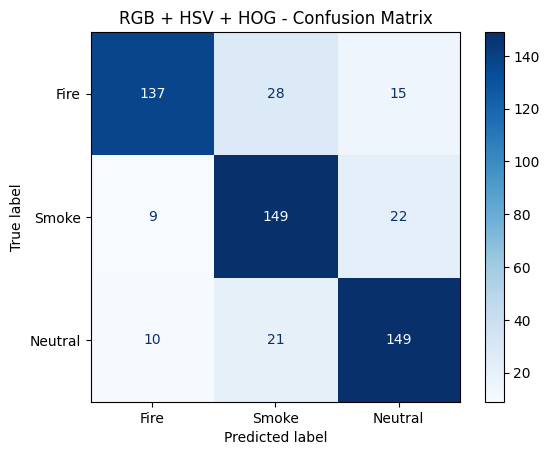

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_combined,
    display_labels=classes,
    cmap="Blues",
    values_format="d"
)

plt.title("RGB + HSV + HOG - Confusion Matrix")
plt.show()

### LBP

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import local_binary_pattern

from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    recall_score
)

In [15]:
P = 8
R = 1

def extract_lbp_features(image_path):

    img = cv2.imread(str(image_path))

    if img is None:
        raise ValueError(f"Cannot read image: {image_path}")

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    gray = cv2.resize(
        gray,
        (128, 128),
        interpolation=cv2.INTER_AREA
    )

    lbp = local_binary_pattern(
        gray,
        P=P,
        R=R,
        method="uniform"
    )

    hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, P + 3),
        range=(0, P + 2)
    )

    hist = hist.astype(np.float32)
    hist /= hist.sum() + 1e-8

    return hist

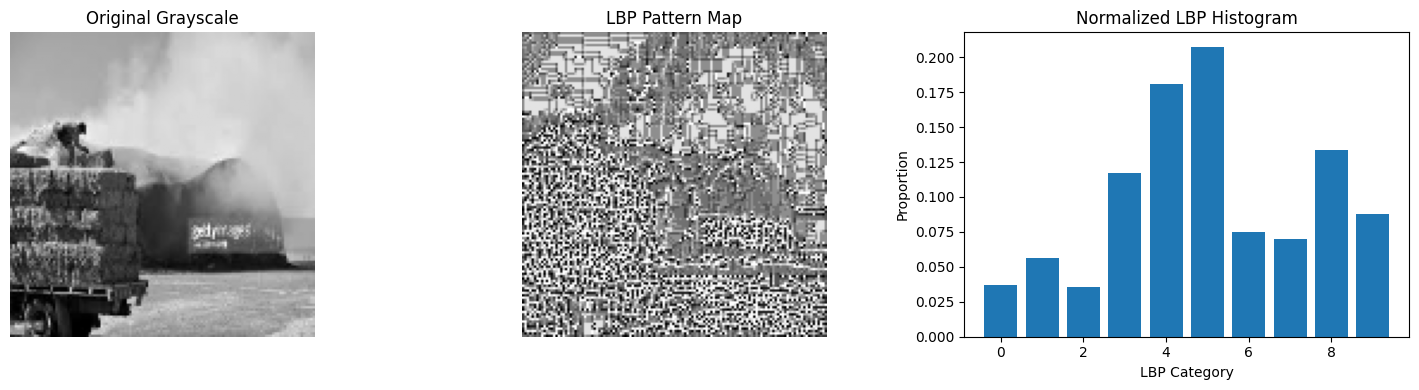

LBP features: [0.03686523 0.05596924 0.03552246 0.11688232 0.18109131 0.20739746
 0.07525635 0.07006836 0.13348389 0.08746338]
Feature count: 10


In [18]:
image_path = train_paths[0]

img = cv2.imread(str(image_path))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = cv2.resize(gray, (128, 128))

lbp = local_binary_pattern(
    gray,
    P=8,
    R=1,
    method="uniform"
)

features = extract_lbp_features(image_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original Grayscale")

axes[1].imshow(lbp, cmap="gray")
axes[1].set_title("LBP Pattern Map")

axes[2].bar(np.arange(len(features)), features)
axes[2].set_title("Normalized LBP Histogram")
axes[2].set_xlabel("LBP Category")
axes[2].set_ylabel("Proportion")

for ax in axes[:2]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("LBP features:", features)
print("Feature count:", len(features))

In [19]:
X_train_lbp = np.vstack([
    extract_lbp_features(path)
    for path in train_paths
])

X_val_lbp = np.vstack([
    extract_lbp_features(path)
    for path in val_paths
])

print("Training:", X_train_lbp.shape)
print("Validation:", X_val_lbp.shape)

Training: (2160, 10)
Validation: (540, 10)


LBP Accuracy: 0.6722222222222223
              precision    recall  f1-score   support

        Fire       0.61      0.61      0.61       180
       Smoke       0.63      0.49      0.55       180
     Neutral       0.75      0.92      0.82       180

    accuracy                           0.67       540
   macro avg       0.66      0.67      0.66       540
weighted avg       0.66      0.67      0.66       540



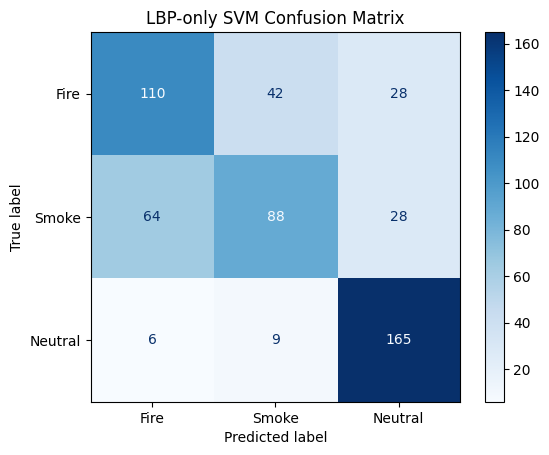

In [20]:
lbp_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
)

lbp_svm.fit(X_train_lbp, y_train)

y_pred_lbp = lbp_svm.predict(X_val_lbp)

print("LBP Accuracy:",
      accuracy_score(y_val, y_pred_lbp))

print(
    classification_report(
        y_val,
        y_pred_lbp,
        target_names=classes
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_lbp,
    display_labels=classes,
    cmap="Blues"
)

plt.title("LBP-only SVM Confusion Matrix")
plt.show()

In [23]:


# X_train_hog = np.vstack([
#     extract_hog_features(p) for p in train_paths
# ])

# X_val_hog = np.vstack([
#     extract_hog_features(p) for p in val_paths
# ])

In [24]:
def scale_and_weight(train, val):
    scaler = StandardScaler()

    train_scaled = scaler.fit_transform(train)
    val_scaled = scaler.transform(val)

    weight = np.sqrt(train.shape[1])

    return train_scaled / weight, val_scaled / weight


feature_groups = [
    (X_train_color, X_val_color),
    (X_train_hog, X_val_hog),
    (X_train_lbp, X_val_lbp)
]

scaled_groups = [
    scale_and_weight(train, val)
    for train, val in feature_groups
]

X_train_all = np.hstack([
    train for train, val in scaled_groups
])

X_val_all = np.hstack([
    val for train, val in scaled_groups
])

print("Combined training:", X_train_all.shape)
print("Combined validation:", X_val_all.shape)

Combined training: (2160, 8206)
Combined validation: (540, 8206)


Combined Accuracy: 0.8537037037037037
              precision    recall  f1-score   support

        Fire       0.91      0.78      0.84       180
       Smoke       0.82      0.83      0.83       180
     Neutral       0.84      0.94      0.89       180

    accuracy                           0.85       540
   macro avg       0.86      0.85      0.85       540
weighted avg       0.86      0.85      0.85       540



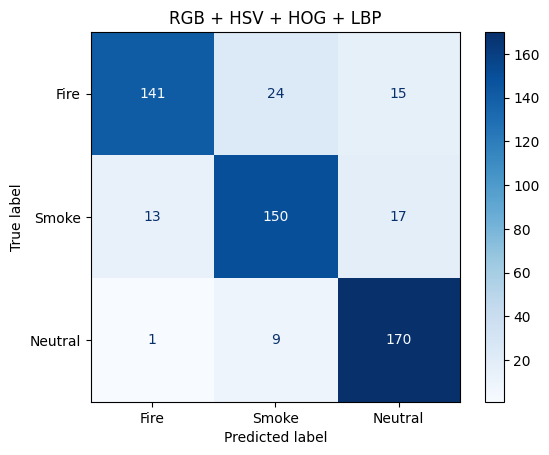

In [25]:
all_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

all_svm.fit(X_train_all, y_train)

y_pred_all = all_svm.predict(X_val_all)

print("Combined Accuracy:",
      accuracy_score(y_val, y_pred_all))

print(
    classification_report(
        y_val,
        y_pred_all,
        target_names=classes
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_all,
    display_labels=classes,
    cmap="Blues"
)

plt.title("RGB + HSV + HOG + LBP")
plt.show()

### Observation
Features
- Color - RGB + HSV
- Shape - HOG
- Texture - LBP

## Hyperparameter tuning

In [27]:
SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

SVC()

In [28]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ["scale", 0.001, 0.01]
}

grid = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1
)

grid.fit(X_train_all, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation F1:", grid.best_score_)

best_model = grid.best_estimator_

y_pred_tuned = best_model.predict(X_val_all)

print(
    classification_report(
        y_val,
        y_pred_tuned,
        target_names=classes
    )
)

Best parameters: {'C': 10, 'gamma': 'scale'}
Best cross-validation F1: 0.8256265485548201
              precision    recall  f1-score   support

        Fire       0.91      0.82      0.86       180
       Smoke       0.82      0.84      0.83       180
     Neutral       0.87      0.93      0.90       180

    accuracy                           0.86       540
   macro avg       0.87      0.86      0.86       540
weighted avg       0.87      0.86      0.86       540



In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

def weight_features(X):
    return X / np.sqrt(X.shape[1])

def group_pipeline():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("weight", FunctionTransformer(weight_features))
    ])

preprocessor = ColumnTransformer([
    ("color", group_pipeline(), slice(0, 96)),
    ("hog", group_pipeline(), slice(96, 8196)),
    ("lbp", group_pipeline(), slice(8196, 8206))
])

pipeline = Pipeline([
    ("features", preprocessor),
    ("svm", SVC(kernel="rbf"))
])

X_train_raw = np.hstack([
    X_train_color,
    X_train_hog,
    X_train_lbp
])

X_val_raw = np.hstack([
    X_val_color,
    X_val_hog,
    X_val_lbp
])

grid = GridSearchCV(
    pipeline,
    {
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.001, 0.01]
    },
    scoring="f1_macro",
    cv=3,
    n_jobs=-1
)

grid.fit(X_train_raw, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV score:", grid.best_score_)

y_pred = grid.predict(X_val_raw)

print(classification_report(
    y_val,
    y_pred,
    target_names=classes
))

Best parameters: {'svm__C': 10, 'svm__gamma': 'scale'}
Best CV score: 0.8256401908832721
              precision    recall  f1-score   support

        Fire       0.91      0.82      0.86       180
       Smoke       0.82      0.84      0.83       180
     Neutral       0.87      0.93      0.90       180

    accuracy                           0.86       540
   macro avg       0.87      0.86      0.86       540
weighted avg       0.87      0.86      0.86       540



In [30]:
# import joblib
# from pathlib import Path

# MODEL_DIR = DATA_DIR / "models"
# MODEL_DIR.mkdir(parents=True, exist_ok=True)

# best_pipeline = grid.best_estimator_

# joblib.dump(
#     best_pipeline,
#     MODEL_DIR / "fire_classifier_svm.joblib"
# )

# print("Saved:", MODEL_DIR / "fire_classifier_svm.joblib")